# Tutorial: Predicting In-Hospital Death for Heart-Failure Patients (MIMIC-III)

**Goal:** use data available early in a hospital stay (age, sex, admission info, and the first lab results)
to predict whether a heart-failure patient dies in the hospital. We compare two scikit-learn models:
**logistic regression** and a **random forest**.

**Data:** full MIMIC-III v1.4 on Google BigQuery (`physionet-data.mimiciii_clinical`).
You need credentialed PhysioNet access linked to your Google account.

**Steps**
1. Connect to BigQuery
2. Pull the cohort + features with one SQL query
3. Explore and clean the data
4. Split into train / test sets
5. Train logistic regression and random forest
6. Evaluate (accuracy, ROC AUC, confusion matrix, ROC curve)
7. Look at which features matter


## Step 0: Imports
Install once with: `pip install google-cloud-bigquery db-dtypes pandas scikit-learn matplotlib seaborn`

In [1]:
import warnings
warnings.filterwarnings("ignore")        # hide library warnings to keep output clean

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from google.cloud import bigquery

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, roc_auc_score, confusion_matrix, classification_report, RocCurveDisplay

## Step 1: Connect to BigQuery
Log in once from a terminal with `gcloud auth application-default login`
(in Google Colab use `from google.colab import auth; auth.authenticate_user()` instead).
Replace the project ID with **your own** Google Cloud project; it is only used for billing/quota.

In [2]:
PROJECT_ID = "your-gcp-project-id"   # <-- change this to your own project
client = bigquery.Client(project=PROJECT_ID)

## Step 2: Pull the data with SQL
One query builds everything:
- **cohort**: adult admissions (18+) with any heart-failure diagnosis (ICD-9 codes starting with 428)
- **first_labs**: the *first* value of 6 common blood tests during each admission
  (creatinine, sodium, potassium, urea nitrogen / BUN, hemoglobin, white blood cells)
- the label **`died`** = `hospital_expire_flag` (1 = died in hospital)

We use only the *first* lab value so the model only sees information from early in the stay.

In [3]:
sql = """
WITH cohort AS (
  SELECT a.hadm_id, a.admittime, a.admission_type, a.insurance, a.hospital_expire_flag AS died,
         p.gender,
         -- age at admission; MIMIC shifts ages over 89 to ~300, so cap at 90
         LEAST(DATE_DIFF(DATE(a.admittime), DATE(p.dob), DAY) / 365.25, 90) AS age
  FROM `physionet-data.mimiciii_clinical.admissions` a
  JOIN `physionet-data.mimiciii_clinical.patients` p USING (subject_id)
  WHERE a.hadm_id IN (SELECT hadm_id FROM `physionet-data.mimiciii_clinical.diagnoses_icd`
                      WHERE icd9_code LIKE '428%')
    AND DATE_DIFF(DATE(a.admittime), DATE(p.dob), DAY) / 365.25 >= 18
),
first_labs AS (
  -- rank each lab result by time within the admission and keep the first one
  SELECT hadm_id, itemid, valuenum
  FROM `physionet-data.mimiciii_clinical.labevents`
  WHERE itemid IN (50912, 50983, 50971, 51006, 51222, 51301)
    AND valuenum IS NOT NULL
    AND hadm_id IN (SELECT hadm_id FROM cohort)
  QUALIFY ROW_NUMBER() OVER (PARTITION BY hadm_id, itemid ORDER BY charttime) = 1
)
SELECT c.hadm_id, c.age, c.gender, c.admission_type, c.insurance, c.died,
       MAX(IF(l.itemid = 50912, l.valuenum, NULL)) AS creatinine,
       MAX(IF(l.itemid = 50983, l.valuenum, NULL)) AS sodium,
       MAX(IF(l.itemid = 50971, l.valuenum, NULL)) AS potassium,
       MAX(IF(l.itemid = 51006, l.valuenum, NULL)) AS bun,
       MAX(IF(l.itemid = 51222, l.valuenum, NULL)) AS hemoglobin,
       MAX(IF(l.itemid = 51301, l.valuenum, NULL)) AS wbc
FROM cohort c
LEFT JOIN first_labs l USING (hadm_id)
GROUP BY c.hadm_id, c.age, c.gender, c.admission_type, c.insurance, c.died
"""
df = client.query(sql).to_dataframe()
print("rows (admissions):", len(df))
print("columns:", list(df.columns))

rows (admissions): 13593
columns: ['hadm_id', 'age', 'gender', 'admission_type', 'insurance', 'died', 'creatinine', 'sodium', 'potassium', 'bun', 'hemoglobin', 'wbc']


## Step 3: Explore and clean
First check how many patients died (the class balance) and how much lab data is missing.

In [4]:
print("in-hospital deaths:", df["died"].sum(), f"({100 * df['died'].mean():.1f}%)")
print("\nmissing values per column (%):")
print((100 * df.isna().mean()).round(1).to_string())

in-hospital deaths: 1969 (14.5%)

missing values per column (%):
hadm_id           0.0
age               0.0
gender            0.0
admission_type    0.0
insurance         0.0
died              0.0
creatinine        0.9
sodium            1.0
potassium         1.0
bun               0.9
hemoglobin        0.9
wbc               0.9


In [5]:
# Summary statistics of the numeric features (no patient-level rows)
df.drop(columns=["hadm_id"]).describe().round(1)

,age,died,creatinine,sodium,potassium,bun,hemoglobin,wbc
count,13593.0,13593.0,13468.0,13462.0,13462.0,13468.0,13466.0,13466.0
mean,72.1,0.1,1.9,138.0,4.5,36.3,11.3,11.7
std,13.5,0.4,1.8,5.1,0.9,25.4,2.2,12.4
min,18.3,0.0,0.0,96.0,1.6,2.0,0.0,0.1
25%,63.3,0.0,0.9,135.0,3.9,19.0,9.8,7.3
50%,74.4,0.0,1.3,138.0,4.3,28.0,11.2,10.0
75%,82.8,0.0,2.1,141.0,4.9,46.0,12.7,13.8
max,90.0,1.0,22.2,177.0,10.4,272.0,20.9,846.7


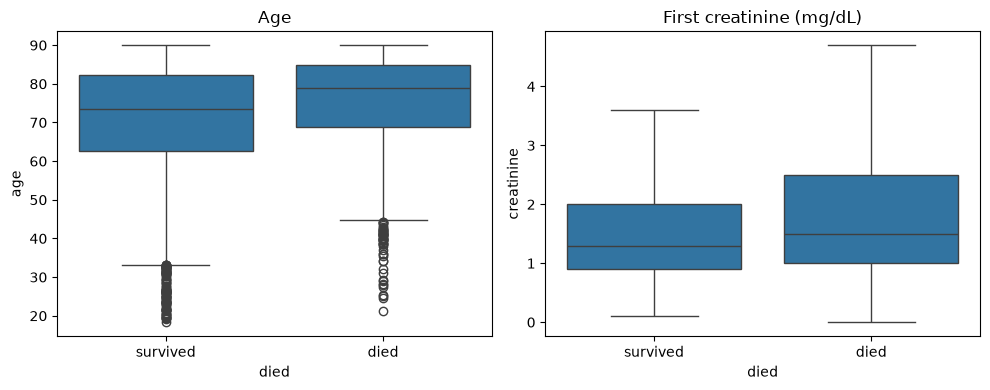

In [6]:
# Compare first creatinine and age between patients who survived vs died
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sns.boxplot(data=df, x="died", y="age", ax=axes[0])
sns.boxplot(data=df, x="died", y="creatinine", ax=axes[1], showfliers=False)
axes[0].set_xticklabels(["survived", "died"]); axes[1].set_xticklabels(["survived", "died"])
axes[0].set_title("Age"); axes[1].set_title("First creatinine (mg/dL)")
plt.tight_layout(); plt.savefig("fig_explore.png", dpi=150); plt.show()

**Cleaning / encoding**
- Categorical columns (gender, admission type, insurance) are turned into 0/1 columns with `pd.get_dummies`.
- Missing lab values are filled with the median later, inside the model pipeline (so the median comes from the training set only).

In [7]:
X = pd.get_dummies(df.drop(columns=["hadm_id", "died"]),
                   columns=["gender", "admission_type", "insurance"], drop_first=True, dtype=int)
y = df["died"]
print("feature columns:", list(X.columns))

feature columns: ['age', 'creatinine', 'sodium', 'potassium', 'bun', 'hemoglobin', 'wbc', 'gender_M', 'admission_type_EMERGENCY', 'admission_type_URGENT', 'insurance_Medicaid', 'insurance_Medicare', 'insurance_Private', 'insurance_Self Pay']


## Step 4: Train / test split
Hold out 25% of admissions for testing. `stratify=y` keeps the same death rate in both sets,
and `random_state=42` makes the split reproducible.

In [8]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=42)
print("train:", X_train.shape, "| test:", X_test.shape)

train: (10194, 14) | test: (3399, 14)


## Step 5: Train the two models
- **Logistic regression**: a simple linear model. Needs scaled features, so the pipeline is impute -> scale -> model.
- **Random forest**: many decision trees voting together; handles non-linear effects and does not need scaling.

Only ~14% of patients died, so both models use `class_weight="balanced"` to pay more attention to the smaller class.

In [9]:
logreg = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                       LogisticRegression(max_iter=1000, class_weight="balanced"))
forest = make_pipeline(SimpleImputer(strategy="median"),
                       RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
                                              class_weight="balanced", random_state=42, n_jobs=-1))
logreg.fit(X_train, y_train)
forest.fit(X_train, y_train)
print("both models trained")

both models trained


## Step 6: Evaluate on the test set
- **Accuracy**: % of predictions that are correct (can be misleading when classes are unbalanced).
- **ROC AUC**: how well the model ranks patients who died above those who survived (0.5 = random, 1.0 = perfect).
- **Confusion matrix**: counts of correct / incorrect predictions for each class.

In [10]:
results = []
for name, model in [("Logistic regression", logreg), ("Random forest", forest)]:
    pred = model.predict(X_test)
    prob = model.predict_proba(X_test)[:, 1]
    results.append({"model": name,
                    "accuracy": round(accuracy_score(y_test, pred), 3),
                    "roc_auc": round(roc_auc_score(y_test, prob), 3)})
    print(f"=== {name} ===")
    print(classification_report(y_test, pred, target_names=["survived", "died"], digits=2))
pd.DataFrame(results)

=== Logistic regression ===
              precision    recall  f1-score   support

    survived       0.90      0.57      0.70      2907
        died       0.20      0.64      0.30       492

    accuracy                           0.58      3399
   macro avg       0.55      0.60      0.50      3399
weighted avg       0.80      0.58      0.64      3399

=== Random forest ===
              precision    recall  f1-score   support

    survived       0.89      0.80      0.84      2907
        died       0.25      0.39      0.31       492

    accuracy                           0.74      3399
   macro avg       0.57      0.60      0.57      3399
weighted avg       0.79      0.74      0.76      3399



,model,accuracy,roc_auc
0,Logistic regression,0.579,0.643
1,Random forest,0.742,0.667


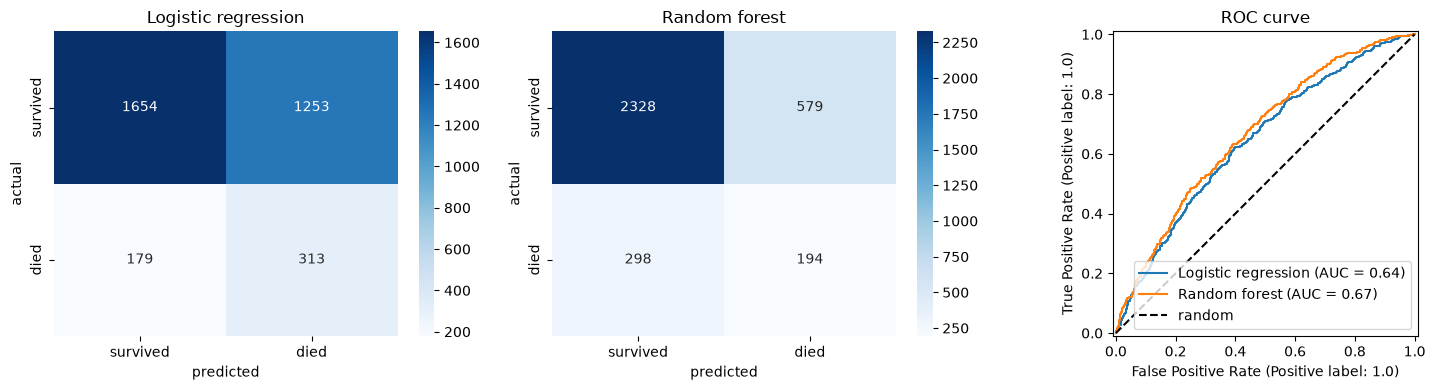

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, model) in zip(axes[:2], [("Logistic regression", logreg), ("Random forest", forest)]):
    cm = confusion_matrix(y_test, model.predict(X_test))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax,
                xticklabels=["survived", "died"], yticklabels=["survived", "died"])
    ax.set_xlabel("predicted"); ax.set_ylabel("actual"); ax.set_title(name)
RocCurveDisplay.from_estimator(logreg, X_test, y_test, ax=axes[2], name="Logistic regression")
RocCurveDisplay.from_estimator(forest, X_test, y_test, ax=axes[2], name="Random forest")
axes[2].plot([0, 1], [0, 1], "k--", label="random"); axes[2].set_title("ROC curve"); axes[2].legend()
plt.tight_layout(); plt.savefig("fig_eval.png", dpi=150); plt.show()

## Step 7: Which features matter?
- Logistic regression: coefficients (features were scaled, so sizes are comparable; positive = higher risk).
- Random forest: built-in feature importance (how much each feature helps split the trees).

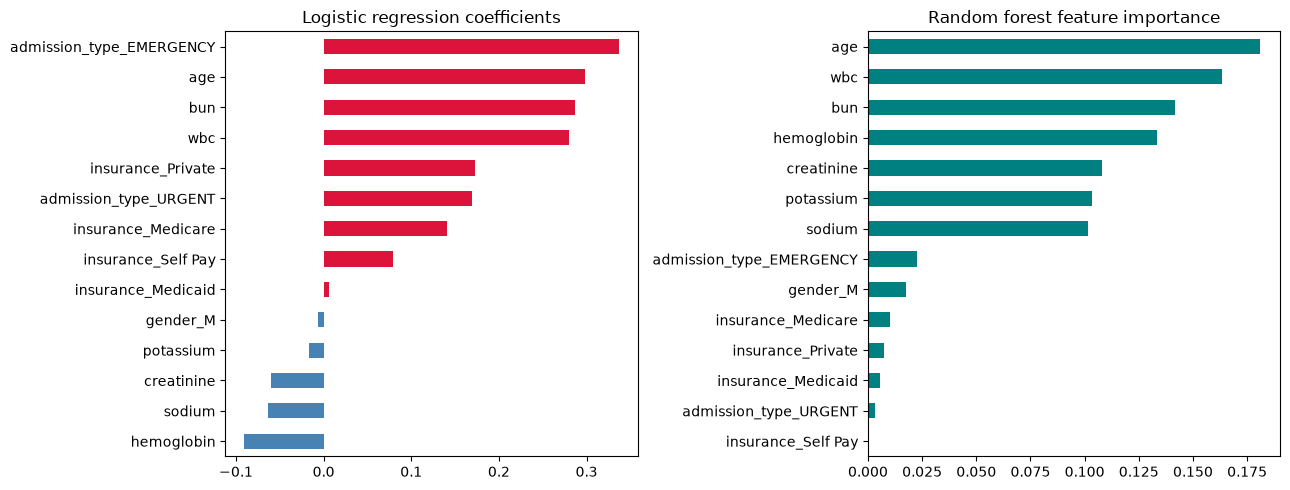

top 5 random forest features:
age           0.181
wbc           0.163
bun           0.142
hemoglobin    0.134
creatinine    0.108


In [12]:
coefs = pd.Series(logreg[-1].coef_[0], index=X.columns).sort_values()
importances = pd.Series(forest[-1].feature_importances_, index=X.columns).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
coefs.plot.barh(ax=axes[0], color=["crimson" if v > 0 else "steelblue" for v in coefs])
axes[0].set_title("Logistic regression coefficients")
importances.plot.barh(ax=axes[1], color="teal"); axes[1].set_title("Random forest feature importance")
plt.tight_layout(); plt.savefig("fig_features.png", dpi=150); plt.show()
print("top 5 random forest features:"); print(importances.sort_values(ascending=False).head(5).round(3).to_string())

## Summary
- We predicted in-hospital death for adult heart-failure admissions in MIMIC-III using only age, sex, admission info and first lab values.
- Both models beat chance but only modestly: ROC AUC 0.64 (logistic regression) and 0.67 (random forest).
- The random forest has higher accuracy (0.74 vs 0.58) because it flags fewer patients; logistic regression catches more deaths (recall 0.64 vs 0.39).
- Age, WBC, BUN, hemoglobin and creatinine are the most useful features. Six first labs are not enough for a strong model.
- Ideas to extend: add vital signs from `chartevents`, add comorbidities from `diagnoses_icd`, or try gradient boosting.